# Лабораторная работа №1. Метод k ближайших соседей

## Цель работы

В этой работе я исследую KNN для классификации и регрессии.
Сравниваю модели sklearn и реализации на NumPy с исходными
настройками и после подбора параметров.

## Задачи и данные

1. Классификация: прогноз покупки туристической страховки.
   Датасет: Travel Insurance Prediction Data.
   Целевая переменная: TravelInsurance.

2. Регрессия: прогноз цены ноутбука в евро.
   Датасет: Laptop Prices.
   Целевая переменная: Price_euros.

### Для чего нужны эти задачи

**Страховка.** Прогноз покупки может помочь страховой компании выбрать,
каким клиентам предложить туристическую страховку. Входные признаки — возраст, доход, занятость, состав семьи
и сведения о поездках. Цель — определить, купит ли клиент страховку. В наборе есть и числовые,
и категориальные признаки, поэтому можно сравнить способы их подготовки для KNN.
[Источник Travel Insurance Prediction Data](https://www.kaggle.com/datasets/tejashvi14/travel-insurance-prediction-data).

**Ноутбуки.** По характеристикам товара оцениваем цену в евро. Такую оценку
можно использовать для сравнения предложений с похожими характеристиками.
В наборе указаны исторические цены. Среди признаков — экран, RAM,
накопители, CPU, GPU и производитель.
[Источник Laptop Prices](https://www.kaggle.com/datasets/owm4096/laptop-prices).

Выбранные наборы сохраняются для всех пяти лабораторных работ.
Размеры и качество данных проверяются ниже. Исходные CSV сохраняются
без изменений; преобразования выполняются в рабочих копиях.

## Проверка окружения

Импортируем библиотеки и сохраняем их версии для воспроизводимости.

In [1]:
# Проверяем Python и библиотеки для выполнения лабораторной работы.
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

# Фиксируем начальное состояние генератора случайных чисел.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("\nОкружение готово.")

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1

Окружение готово.


## Загрузка и первичная проверка данных

Загружаем исходные CSV. Проверяем размеры таблиц, пропуски,
повторяющиеся строки и распределение целевой переменной.

Служебный индекс исключаем из признаков после проверки.
Исходные файлы сохраняем без изменений.


In [2]:
# Загружаем два исходных CSV с компьютера в среду Colab.
from google.colab import files

uploaded = files.upload()

Saving laptop_prices.csv to laptop_prices.csv
Saving TravelInsurancePrediction.csv to TravelInsurancePrediction.csv


In [3]:
# Читаем загруженные CSV.
travel_raw = pd.read_csv("TravelInsurancePrediction.csv")
laptops_raw = pd.read_csv("laptop_prices.csv")

# Создаём рабочие копии, сохраняя исходные таблицы.
travel = travel_raw.copy()
laptops = laptops_raw.copy()

# Проверяем, что безымянный столбец — последовательный индекс.
if "Unnamed: 0" in travel.columns:
    assert np.array_equal(
        travel["Unnamed: 0"].to_numpy(),
        np.arange(len(travel))
    ), "Столбец требует дополнительной проверки."

    travel = travel.drop(columns="Unnamed: 0")
    print("Служебный индекс страховки исключён.")

# Проверяем размер, пропуски и полные повторы строк.
for name, df in [
    ("Туристическая страховка", travel),
    ("Цены ноутбуков", laptops)
]:
    print(f"\n{name}")
    print("Размер таблицы:", df.shape)
    print("Пропущенных значений:", df.isna().sum().sum())
    print("Повторных строк:", df.duplicated().sum())
    display(df.head(3))

# Проверяем количество объектов каждого класса.
print("\nРаспределение TravelInsurance:")
print(travel["TravelInsurance"].value_counts().sort_index())

Служебный индекс страховки исключён.

Туристическая страховка
Размер таблицы: (1987, 9)
Пропущенных значений: 0
Повторных строк: 738


,Age,Employment Type,GraduateOrNot,AnnualIncome,FamilyMembers,ChronicDiseases,FrequentFlyer,EverTravelledAbroad,TravelInsurance
0,31,Government Sector,Yes,400000,6,1,No,No,0
1,31,Private Sector/Self Employed,Yes,1250000,7,0,No,No,0
2,34,Private Sector/Self Employed,Yes,500000,4,1,No,No,1



Цены ноутбуков
Размер таблицы: (1275, 23)
Пропущенных значений: 0
Повторных строк: 0


,Company,Product,TypeName,Inches,Ram,OS,Weight,Price_euros,Screen,ScreenW,...,RetinaDisplay,CPU_company,CPU_freq,CPU_model,PrimaryStorage,SecondaryStorage,PrimaryStorageType,SecondaryStorageType,GPU_company,GPU_model
0,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1.37,1339.69,Standard,2560,...,Yes,Intel,2.3,Core i5,128,0,SSD,No,Intel,Iris Plus Graphics 640
1,Apple,Macbook Air,Ultrabook,13.3,8,macOS,1.34,898.94,Standard,1440,...,No,Intel,1.8,Core i5,128,0,Flash Storage,No,Intel,HD Graphics 6000
2,HP,250 G6,Notebook,15.6,8,No OS,1.86,575.00,Full HD,1920,...,No,Intel,2.5,Core i5 7200U,256,0,SSD,No,Intel,HD Graphics 620



Распределение TravelInsurance:
TravelInsurance
0    1277
1     710
Name: count, dtype: int64


## Подготовка признаков и разделение данных

Повторяющиеся строки не удаляются. Строки с одинаковыми входными
признаками относятся к одной группе. Группа целиком попадает в train или test.
Целевая переменная при формировании групп не используется.

При разделении страховки также учитываются доли классов.
Размер теста около 20%; точная доля зависит от размера групп.

Для регрессии исключаем Product, CPU_model и GPU_model, чтобы ограничить
число редких категорий. Остальные характеристики оставляем.

Разбиения фиксируются для всех пяти лабораторных.
Подбор параметров будет выполняться только на обучающей части,
с учётом групп внутри кросс-валидации.


In [4]:
# Импортируем методы разделения с учётом групп.
from pathlib import Path
from sklearn.model_selection import (
    StratifiedGroupKFold,
    GroupShuffleSplit,
    GroupKFold,
)

# Отделяем входные признаки от целевых переменных.
X_cls = travel.drop(columns="TravelInsurance").copy()
y_cls = travel["TravelInsurance"].copy()

X_reg = laptops.drop(
    columns=["Price_euros", "Product", "CPU_model", "GPU_model"]
).copy()
y_reg = laptops["Price_euros"].copy()

# Одинаковые входные профили получают один номер группы.
# Целевые переменные в группы не входят.
groups_cls = pd.factorize(pd.MultiIndex.from_frame(X_cls))[0]
groups_reg = pd.factorize(pd.MultiIndex.from_frame(X_reg))[0]

# Для классификации заранее выбираем первую из пяти частей как тест.
# Метод учитывает группы и стремится сохранить соотношение классов.
split_cls = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
train_idx_cls, test_idx_cls = next(
    split_cls.split(X_cls, y_cls, groups=groups_cls)
)

# Для регрессии случайно выделяем 20% групп в тест.
split_reg = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE
)
train_idx_reg, test_idx_reg = next(
    split_reg.split(X_reg, y_reg, groups=groups_reg)
)

# Создаём обучающие и тестовые выборки.
X_train_cls, X_test_cls = (
    X_cls.iloc[train_idx_cls].copy(),
    X_cls.iloc[test_idx_cls].copy(),
)
y_train_cls, y_test_cls = (
    y_cls.iloc[train_idx_cls].copy(),
    y_cls.iloc[test_idx_cls].copy(),
)

X_train_reg, X_test_reg = (
    X_reg.iloc[train_idx_reg].copy(),
    X_reg.iloc[test_idx_reg].copy(),
)
y_train_reg, y_test_reg = (
    y_reg.iloc[train_idx_reg].copy(),
    y_reg.iloc[test_idx_reg].copy(),
)

# Группы обучающей части понадобятся при подборе параметров.
groups_train_cls = groups_cls[train_idx_cls]
groups_train_reg = groups_reg[train_idx_reg]

cv_cls = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE
)
cv_reg = GroupKFold(n_splits=3)

# Проверяем отсутствие пересечений и сохраняем номера исходных строк.
split_dir = Path("/content/data/splits")
split_dir.mkdir(parents=True, exist_ok=True)

for name, X, groups, train_idx, test_idx in [
    ("travel", X_cls, groups_cls, train_idx_cls, test_idx_cls),
    ("laptops", X_reg, groups_reg, train_idx_reg, test_idx_reg),
]:
    overlap = set(groups[train_idx]) & set(groups[test_idx])
    assert not overlap, f"Обнаружено пересечение групп: {name}"

    assignment = np.full(len(X), "train", dtype=object)
    assignment[test_idx] = "test"

    pd.DataFrame({
        "row_position": np.arange(len(X)),
        "group_id": groups,
        "subset": assignment,
    }).to_csv(split_dir / f"{name}_split.csv", index=False)

    print(f"\n{name}:")
    print("Обучение:", len(train_idx), "Тест:", len(test_idx))
    print(f"Доля теста: {len(test_idx) / len(X):.1%}")
    print("Пересечений групп:", len(overlap))

# Проверяем распределение классов после разделения.
print("\nДоли классов страховки:")
display(pd.DataFrame({
    "train": y_train_cls.value_counts(normalize=True),
    "test": y_test_cls.value_counts(normalize=True),
}).sort_index())


travel:
Обучение: 1543 Тест: 444
Доля теста: 22.3%
Пересечений групп: 0

laptops:
Обучение: 1009 Тест: 266
Доля теста: 20.9%
Пересечений групп: 0

Доли классов страховки:


,train,test
TravelInsurance,,
0,0.637719,0.65991
1,0.362281,0.34009


## Сохранение разбиений

Сохраняем номера строк обучающей и тестовой частей, параметры
разделения и контрольные суммы исходных файлов. Эти разбиения
будут использоваться во всех пяти лабораторных работах.


In [5]:
# Сохраняем описание разбиений и версии библиотек.
import hashlib
import json
import shutil

manifest = {
    "random_state": RANDOM_STATE,
    "classification_split": {
        "method": "StratifiedGroupKFold",
        "n_splits": 5,
        "test_fold": 0,
    },
    "regression_split": {
        "method": "GroupShuffleSplit",
        "test_size_groups": 0.2,
    },
    "classification_features": X_cls.columns.tolist(),
    "regression_features": X_reg.columns.tolist(),
    "versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
    },
    "source_sha256": {
        name: hashlib.sha256(Path(name).read_bytes()).hexdigest()
        for name in [
            "TravelInsurancePrediction.csv",
            "laptop_prices.csv",
        ]
    },
}

(split_dir / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Упаковываем две таблицы разбиения и описание в один архив.
archive_path = shutil.make_archive(
    "/content/fixed_splits",
    "zip",
    root_dir=str(split_dir),
)

files.download(archive_path)
print("Архив разбиений подготовлен.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Архив разбиений подготовлен.


## Исследование обучающих данных

Изучаем распределение классов, доходов клиентов и цен ноутбуков.
Тестовые данные при исследовании признаков не используем.

Для классификации основной метрикой выбираем macro-F1:
F1 рассчитывается отдельно для двух классов, затем берётся среднее.
Поэтому больший класс не получает большего веса в итоговой метрике.

Для регрессии основной метрикой выбираем MAE:
она показывает среднюю абсолютную ошибку прогноза в евро.
Дополнительно будем оценивать RMSE и R².


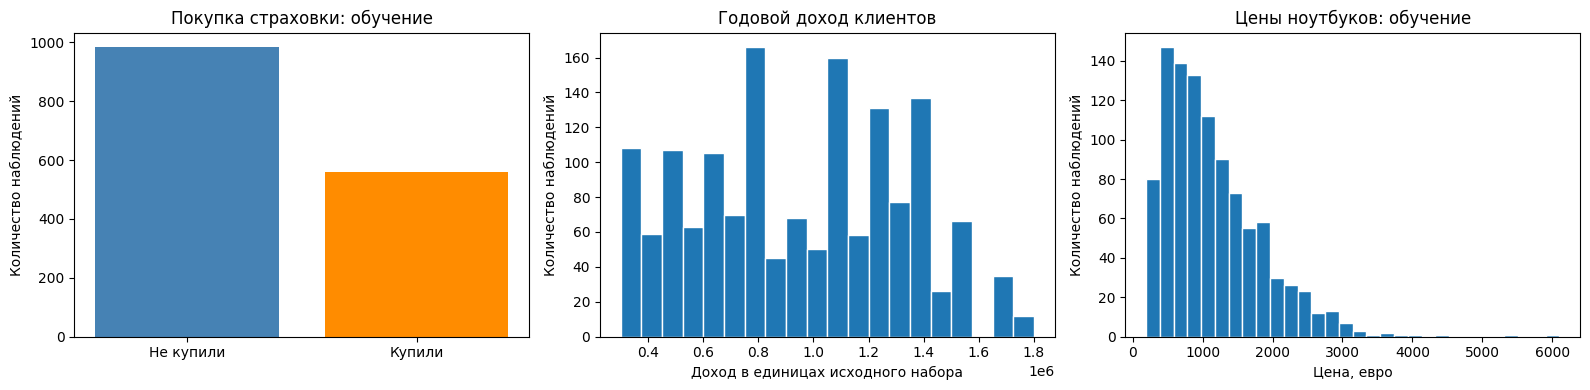

Статистика цены на обучающей части, евро:


,Price_euros
count,1009.00
mean,1148.83
std,705.46
min,191.90
25%,614.00
50%,989.00
75%,1499.00
95%,2481.94
max,6099.00


In [6]:
# Строим графики только по обучающим данным.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

class_counts = y_train_cls.value_counts().sort_index()
axes[0].bar(
    ["Не купили", "Купили"],
    class_counts.to_numpy(),
    color=["steelblue", "darkorange"],
)
axes[0].set_title("Покупка страховки: обучение")
axes[0].set_ylabel("Количество наблюдений")

axes[1].hist(
    X_train_cls["AnnualIncome"],
    bins=20,
    edgecolor="white",
)
axes[1].set_title("Годовой доход клиентов")
axes[1].set_xlabel("Доход в единицах исходного набора")
axes[1].set_ylabel("Количество наблюдений")

axes[2].hist(y_train_reg, bins=30, edgecolor="white")
axes[2].set_title("Цены ноутбуков: обучение")
axes[2].set_xlabel("Цена, евро")
axes[2].set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()

# Выводим статистику цены для интерпретации графика.
print("Статистика цены на обучающей части, евро:")
display(
    y_train_reg.describe(
        percentiles=[0.25, 0.5, 0.75, 0.95]
    ).round(2)
)

### Выводы первичного исследования

1. В обучающей части покупателей страховки около 36%, поэтому одной
   Accuracy недостаточно: дополнительно важно оценивать оба класса
   с помощью macro-F1.

2. Доход клиентов измеряется сотнями тысяч и миллионами, тогда как
   возраст и размер семьи имеют значительно меньшие значения.
   Проверим гипотезу, что масштабирование улучшает качество KNN.

3. Распределение цен ноутбуков имеет длинный правый хвост.
   Среднее значение — 1148.83 евро, медиана — 989 евро.
   Позже проверим гипотезу обучения на логарифме цены.

4. Высокая цена сама по себе не является ошибкой данных:
   дорогие ноутбуки сохраняем в выборке.


## Исходные модели и оценка на кросс-валидации

Оцениваем модели на трёх частях обучающей выборки.
Группы одинаковых профилей учитываются при разделении.

Для сравнения используются два простых прогноза:

- DummyClassifier всегда предсказывает наиболее частый класс.
- DummyRegressor всегда предсказывает медиану обучающих цен.

Исходный KNN использует стандартные параметры.
Категориальные признаки кодируем методом one-hot.
Числовые признаки пока оставляем в исходном масштабе.

Предобработка обучается отдельно внутри каждой части
кросс-валидации с помощью Pipeline.


In [7]:
# Импортируем инструменты подготовки данных и оценки моделей.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import cross_validate

# Фиксируем части CV: все сравниваемые модели получат одинаковые строки.
cv_folds_cls = list(
    cv_cls.split(X_train_cls, y_train_cls, groups_train_cls)
)
cv_folds_reg = list(
    cv_reg.split(X_train_reg, y_train_reg, groups_train_reg)
)


def make_preprocessor(X):
    """Кодируем категории, сохраняя исходный масштаб числовых признаков."""
    numeric_columns = X.select_dtypes(include="number").columns.tolist()
    categorical_columns = [
        column for column in X.columns
        if column not in numeric_columns
    ]

    return ColumnTransformer([
        ("numeric", "passthrough", numeric_columns),
        ("categorical", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ), categorical_columns),
    ])


def evaluate_models(models, X, y, folds, scoring):
    """Возвращаем средние метрики и их стандартные отклонения по CV."""
    rows = []

    for name, model in models.items():
        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(X)),
            ("model", model),
        ])

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=folds,
            scoring=scoring,
            n_jobs=-1,
            error_score="raise",
        )

        row = {"model": name}

        for metric, scorer in scoring.items():
            values = scores[f"test_{metric}"]

            # В sklearn ошибки возвращаются со знаком минус.
            # Для MAE и RMSE возвращаем положительный знак.
            if scorer.startswith("neg_"):
                values = -values

            row[f"{metric}_mean"] = values.mean()
            row[f"{metric}_std"] = values.std(ddof=1)

        rows.append(row)

    return pd.DataFrame(rows)


# Оцениваем классификацию только на обучающей части.
baseline_cv_cls = evaluate_models(
    models={
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "KNN baseline": KNeighborsClassifier(),
    },
    X=X_train_cls,
    y=y_train_cls,
    folds=cv_folds_cls,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy",
        "roc_auc": "roc_auc",
    },
)

# Оцениваем регрессию на тех же заранее выбранных частях CV.
baseline_cv_reg = evaluate_models(
    models={
        "Dummy": DummyRegressor(strategy="median"),
        "KNN baseline": KNeighborsRegressor(),
    },
    X=X_train_reg,
    y=y_train_reg,
    folds=cv_folds_reg,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2",
    },
)

# Сохраняем фактические результаты без округления.
results_dir = Path("/content/results")
results_dir.mkdir(parents=True, exist_ok=True)

baseline_cv_cls.to_csv(
    results_dir / "lab1_baseline_cv_classification.csv", index=False
)
baseline_cv_reg.to_csv(
    results_dir / "lab1_baseline_cv_regression.csv", index=False
)

print("Классификация: результаты CV")
display(baseline_cv_cls.round(4))

print("Регрессия: результаты CV")
display(baseline_cv_reg.round(4))

Классификация: результаты CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,KNN baseline,0.7499,0.0187,0.7866,0.0148,0.7929,0.0269


Регрессия: результаты CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,KNN baseline,265.2280,12.1810,416.3395,15.9908,0.6509,0.0225


### Результаты исходных моделей

Исходный KNN превосходит простые ориентиры:
- macro-F1 классификации: 0.7499 против 0.3893;
- MAE регрессии: 265.23 евро против 528.92 евро.

### Гипотеза №1. Масштабирование числовых признаков

Признаки имеют разные единицы и масштабы. Предполагаем, что
стандартизация числовых признаков улучшит качество KNN,
изменив вклад признаков в расстояние между объектами.

Меняем только обработку числовых признаков: вместо исходного
масштаба используем StandardScaler. Категориальное кодирование,
параметры KNN и части кросс-валидации сохраняем.

Среднее и стандартное отклонение для масштабирования рассчитываются
внутри Pipeline на обучающей части каждого разбиения CV.


In [8]:
# Проверяем только эффект масштабирования числовых признаков.
from sklearn.preprocessing import StandardScaler


def evaluate_scaled_knn(X, y, folds, model, scoring):
    """Оцениваем KNN с масштабированием на фиксированных частях CV."""
    preprocessor = make_preprocessor(X)

    # Ветка numeric отвечает за числовые признаки.
    # Заменяем passthrough на StandardScaler; кодирование категорий сохраняем.
    preprocessor.set_params(numeric=StandardScaler())

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=folds,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )

    row = {"model": "KNN + StandardScaler"}

    for metric, scorer in scoring.items():
        values = scores[f"test_{metric}"]
        if scorer.startswith("neg_"):
            values = -values

        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)

    return pd.DataFrame([row])


# Проверяем гипотезу для классификации.
scaled_cv_cls = evaluate_scaled_knn(
    X=X_train_cls,
    y=y_train_cls,
    folds=cv_folds_cls,
    model=KNeighborsClassifier(),
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy",
        "roc_auc": "roc_auc",
    },
)

# Проверяем гипотезу для регрессии.
scaled_cv_reg = evaluate_scaled_knn(
    X=X_train_reg,
    y=y_train_reg,
    folds=cv_folds_reg,
    model=KNeighborsRegressor(),
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2",
    },
)

# Объединяем новые результаты с исходными.
scaling_comparison_cls = pd.concat(
    [baseline_cv_cls, scaled_cv_cls], ignore_index=True
)
scaling_comparison_reg = pd.concat(
    [baseline_cv_reg, scaled_cv_reg], ignore_index=True
)

# Сохраняем результаты полной точности.
scaling_comparison_cls.to_csv(
    results_dir / "lab1_scaling_cv_classification.csv", index=False
)
scaling_comparison_reg.to_csv(
    results_dir / "lab1_scaling_cv_regression.csv", index=False
)

print("Классификация: влияние масштабирования")
display(scaling_comparison_cls.round(4))

print("Регрессия: влияние масштабирования")
display(scaling_comparison_reg.round(4))

Классификация: влияние масштабирования


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,Dummy,0.3893,0.0087,0.6378,0.0235,0.5000,0.0000
1,KNN baseline,0.7499,0.0187,0.7866,0.0148,0.7929,0.0269
2,KNN + StandardScaler,0.7465,0.0223,0.7812,0.0190,0.7589,0.0390


Регрессия: влияние масштабирования


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,Dummy,528.9241,8.4828,722.8491,14.0135,-0.0517,0.0085
1,KNN baseline,265.2280,12.1810,416.3395,15.9908,0.6509,0.0225
2,KNN + StandardScaler,241.1807,6.5586,369.6716,13.0294,0.7239,0.0308


### Вывод по гипотезе №1

Для классификации масштабирование при стандартных параметрах KNN
не улучшило macro-F1: 0.7499 без масштабирования против 0.7465 с ним.

Для регрессии MAE снизилась с 265.23 до 241.18 евро — примерно на 9.1%.
В этой задаче масштабирование помогло.

### Гипотеза №2. Подбор параметров KNN

Далее подбираются число соседей, веса и расстояние.
Сравниваются варианты с масштабированием и без него.

Проверяем:
- число соседей: 3, 5, 9, 15;
- веса: одинаковые или обратно пропорциональные расстоянию;
- расстояние: манхэттенское или евклидово;
- числовые признаки: исходный масштаб или StandardScaler.

Для классификации выбираем вариант по macro-F1,
для регрессии — по MAE. Используем прежние части групповой CV.


In [9]:
# Подбираем параметры внутри Pipeline на фиксированных частях CV.
from sklearn.model_selection import GridSearchCV


def tune_knn(X, y, folds, model, scoring, task_name):
    """Перебираем настройки KNN и сохраняем результаты всех вариантов."""
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(X)),
        ("model", model),
    ])

    param_grid = {
        "preprocessor__numeric": ["passthrough", StandardScaler()],
        "model__n_neighbors": [3, 5, 9, 15],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    }

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=scoring,
        cv=folds,
        refit=True,
        n_jobs=-1,
        error_score="raise",
        verbose=1,
    )
    search.fit(X, y)

    # Сохраняем полную таблицу поиска.
    table = pd.DataFrame(search.cv_results_)
    table.to_csv(
        results_dir / f"lab1_grid_{task_name}.csv",
        index=False,
    )

    # Показываем пять лучших сочетаний.
    top = table.sort_values("rank_test_score").head(5).copy()
    top = top[[
        "param_preprocessor__numeric",
        "param_model__n_neighbors",
        "param_model__weights",
        "param_model__p",
        "mean_test_score",
        "std_test_score",
    ]]

    if scoring.startswith("neg_"):
        top["mean_test_score"] = -top["mean_test_score"]

    metric_name = "MAE, евро" if scoring.startswith("neg_") else "macro-F1"
    top.columns = [
        "Числовая обработка", "k", "Веса", "p",
        f"CV {metric_name}", "Разброс CV",
    ]

    print(f"\nЗадача: {task_name}")
    print("Лучшие параметры:", search.best_params_)
    display(top.round(4))

    return search


# Выбираем параметры классификации по macro-F1.
search_cls = tune_knn(
    X=X_train_cls,
    y=y_train_cls,
    folds=cv_folds_cls,
    model=KNeighborsClassifier(),
    scoring="f1_macro",
    task_name="classification",
)

# Выбираем параметры регрессии по MAE.
search_reg = tune_knn(
    X=X_train_reg,
    y=y_train_reg,
    folds=cv_folds_reg,
    model=KNeighborsRegressor(),
    scoring="neg_mean_absolute_error",
    task_name="regression",
)

Fitting 3 folds for each of 32 candidates, totalling 96 fits

Задача: classification
Лучшие параметры: {'model__n_neighbors': 5, 'model__p': 2, 'model__weights': 'distance', 'preprocessor__numeric': 'passthrough'}


,Числовая обработка,k,Веса,p,CV macro-F1,Разброс CV
14,passthrough,5,distance,2,0.7540,0.0180
30,passthrough,15,distance,2,0.7503,0.0317
12,passthrough,5,uniform,2,0.7499,0.0153
25,StandardScaler(),15,uniform,1,0.7483,0.0167
31,StandardScaler(),15,distance,2,0.7478,0.0272


Fitting 3 folds for each of 32 candidates, totalling 96 fits

Задача: regression
Лучшие параметры: {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance', 'preprocessor__numeric': StandardScaler()}


,Числовая обработка,k,Веса,p,"CV MAE, евро",Разброс CV
11,StandardScaler(),5,distance,1,226.1744,11.6675
19,StandardScaler(),9,distance,1,227.4036,10.8356
23,StandardScaler(),9,distance,2,234.3018,8.4073
15,StandardScaler(),5,distance,2,234.3621,7.6609
3,StandardScaler(),3,distance,1,234.3809,15.8208


### Вывод по подбору параметров

Для классификации лучший результат CV — macro-F1 = 0.7540:
5 соседей, веса по расстоянию, евклидово расстояние,
числовые признаки без масштабирования.

Для регрессии лучший результат CV — MAE = 226.17 евро:
5 соседей, веса по расстоянию, манхэттенское расстояние,
масштабирование числовых признаков StandardScaler.

### Дополнительные гипотезы для регрессии

1. Плотность пикселей экрана PPI может лучше описывать его характеристики,
   чем диагональ и разрешение по отдельности.
   PPI = sqrt(ScreenW² + ScreenH²) / Inches.

2. Обучение на log1p цены может уменьшить влияние дорогих ноутбуков
   на предсказания и улучшить MAE.

Проверяем каждое изменение отдельно и их сочетание.
Подобранные параметры KNN и части CV сохраняем.

Перед расчётом ошибок прогнозы переводятся обратно в евро.


In [10]:
# Проверяем новые признаки и преобразование цены.
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor


def add_screen_density(X):
    """Добавляем PPI только из характеристик экрана."""
    result = X.copy()
    assert (result["Inches"] > 0).all(), "Проверьте диагонали экрана."

    result["PPI"] = (
        np.sqrt(result["ScreenW"] ** 2 + result["ScreenH"] ** 2)
        / result["Inches"]
    )
    return result


# Формула PPI не обучается на данных и не использует целевую цену.
X_train_reg_ppi = add_screen_density(X_train_reg)

# Сохраняем подобранные параметры самого KNN.
tuned_reg_model = clone(
    search_reg.best_estimator_.named_steps["model"]
)

# Преобразуем цену при обучении и возвращаем прогнозы в евро.
log_reg_model = TransformedTargetRegressor(
    regressor=clone(tuned_reg_model),
    func=np.log1p,
    inverse_func=np.expm1,
)

assert (y_train_reg > 0).all(), "Проверьте значения цены."

# Все варианты используют StandardScaler, выбранный для регрессии.
reg_feature_variants = {
    "KNN tuned": (
        X_train_reg,
        clone(tuned_reg_model),
    ),
    "KNN tuned + PPI": (
        X_train_reg_ppi,
        clone(tuned_reg_model),
    ),
    "KNN tuned + log price": (
        X_train_reg,
        clone(log_reg_model),
    ),
    "KNN tuned + PPI + log price": (
        X_train_reg_ppi,
        clone(log_reg_model),
    ),
}

variant_results = []

for name, (X_variant, model_variant) in reg_feature_variants.items():
    result = evaluate_scaled_knn(
        X=X_variant,
        y=y_train_reg,
        folds=cv_folds_reg,
        model=model_variant,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
    )
    result["model"] = name
    variant_results.append(result)

reg_features_cv = pd.concat(variant_results, ignore_index=True)

# Сохраняем фактические результаты полной точности.
reg_features_cv.to_csv(
    results_dir / "lab1_features_cv_regression.csv",
    index=False,
)

print("Дополнительные гипотезы: сравнение на одинаковых частях CV")
display(
    reg_features_cv.sort_values("mae_mean").round(4)
)

Дополнительные гипотезы: сравнение на одинаковых частях CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,KNN tuned,226.1744,14.2897,337.0469,24.8830,0.7694,0.0429
2,KNN tuned + log price,228.6340,13.0568,346.3735,23.0985,0.7568,0.0403
1,KNN tuned + PPI,228.9343,14.4911,339.4111,26.8413,0.7658,0.0471
3,KNN tuned + PPI + log price,230.5736,14.5902,346.4503,23.5724,0.7566,0.0421


### Вывод по дополнительным гипотезам

При выбранных параметрах KNN добавление PPI и преобразование цены
log1p не улучшили среднюю MAE на кросс-валидации.

В улучшенной регрессионной модели сохраняем StandardScaler,
5 соседей, веса по расстоянию и манхэттенское расстояние.
PPI и логарифм цены не используем.

## Собственная реализация KNN

Реализуем самостоятельно:
- хранение обучающих наблюдений;
- вычисление манхэттенского и евклидова расстояний;
- выбор k ближайших соседей;
- одинаковые веса и веса по расстоянию;
- вероятности классов и выбор класса;
- взвешенное среднее для регрессии.

При нулевом расстоянии учитываем только точные совпадения.
При равных голосах выбираем первый класс в отсортированном списке.
При равных расстояниях сохраняем порядок обучающих строк.

Для вычислений используем NumPy. Из sklearn используем интерфейсы
моделей и проверку входных данных. Поиск соседей и расчёт прогнозов
выполняются в коде этих классов.


### Принцип работы собственного алгоритма

На этапе fit сохраняются обучающие признаки и ответы. Для каждого нового
объекта рассчитываются расстояния до всех обучающих объектов:

- при p=1: сумма абсолютных разностей координат;
- при p=2: квадратный корень из суммы квадратов разностей.

Выбираются k объектов с минимальными расстояниями. При uniform вклад
соседей одинаков; при distance веса пропорциональны 1/d. В регрессии
прогноз — взвешенное среднее ответов, в классификации — класс с наибольшей
суммой весов. Вероятности получаются нормировкой этих сумм.

Собственная версия использует полный перебор и устойчивую сортировку:
для одного запроса затраты составляют O(n*d + n*log(n)), где n — число
обучающих строк, d — число обработанных признаков. При равных расстояниях
на границе k выбранные соседи могут отличаться от sklearn, поэтому точного
совпадения всех прогнозов на реальных данных не предполагаем.


In [11]:
"""Собственный KNN: полный перебор соседей, NumPy, две задачи.

Расстояния, выбор соседей, веса и агрегация реализованы здесь.
Из sklearn используются интерфейсы оценщиков и проверка входных данных.
Предобработка категорий и масштабирование остаются снаружи, в Pipeline.
"""

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
from sklearn.utils.multiclass import check_classification_targets
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y


class _BaseKNN(BaseEstimator):
    """Общие параметры, хранение train и поиск ближайших соседей."""

    def __init__(self, n_neighbors=5, weights="uniform", p=2):
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p

    def fit(self, X, y):
        X, y = check_X_y(
            X, y, dtype=np.float64,
            y_numeric=isinstance(self, RegressorMixin),
        )
        if (
            isinstance(self.n_neighbors, (bool, np.bool_))
            or not isinstance(self.n_neighbors, (int, np.integer))
            or not 1 <= self.n_neighbors <= len(X)
        ):
            raise ValueError("n_neighbors должен быть целым числом от 1 до len(X).")
        if self.weights not in ("uniform", "distance"):
            raise ValueError("Допустимые веса: uniform, distance.")
        if self.p not in (1, 2):
            raise ValueError("Поддерживаются p=1 и p=2.")

        # У KNN обучение состоит в сохранении обучающих наблюдений.
        self.X_ = X.copy()
        self.y_ = y.copy()
        self.n_features_in_ = X.shape[1]
        return self

    def _neighbors_and_weights(self, X):
        check_is_fitted(self, ["X_", "y_"])
        X = check_array(X, dtype=np.float64)
        if X.shape[1] != self.n_features_in_:
            raise ValueError("Число признаков отличается от обучающей выборки.")

        for query in X:
            difference = self.X_ - query
            if self.p == 1:
                distances = np.abs(difference).sum(axis=1)
            else:
                distances = np.sqrt((difference ** 2).sum(axis=1))

            # При равных расстояниях сохраняем порядок строк train.
            indices = np.argsort(distances, kind="stable")[:self.n_neighbors]
            neighbor_distances = distances[indices]

            if self.weights == "uniform":
                weights = np.ones(len(indices), dtype=float)
            else:
                exact_matches = neighbor_distances == 0
                if exact_matches.any():
                    # При точных совпадениях учитываем только их.
                    weights = exact_matches.astype(float)
                else:
                    # Относительные веса эквивалентны 1/d, но не превышают 1.
                    weights = neighbor_distances.min() / neighbor_distances

            yield indices, weights / weights.sum()


class MyKNNClassifier(ClassifierMixin, _BaseKNN):
    """Классификация по сумме весов соседей каждого класса."""

    def fit(self, X, y):
        super().fit(X, y)
        check_classification_targets(self.y_)
        self.classes_, self.encoded_y_ = np.unique(
            self.y_, return_inverse=True,
        )
        return self

    def predict_proba(self, X):
        check_is_fitted(self, ["classes_", "encoded_y_"])
        probabilities = []
        for indices, weights in self._neighbors_and_weights(X):
            probabilities.append(np.bincount(
                self.encoded_y_[indices],
                weights=weights,
                minlength=len(self.classes_),
            ))
        return np.asarray(probabilities)

    def predict(self, X):
        # При равных голосах выбираем первый класс в отсортированном classes_.
        probabilities = self.predict_proba(X)
        return self.classes_[probabilities.argmax(axis=1)]


class MyKNNRegressor(RegressorMixin, _BaseKNN):
    """Регрессия через взвешенное среднее целевых значений соседей."""

    def predict(self, X):
        return np.asarray([
            np.dot(weights, self.y_[indices])
            for indices, weights in self._neighbors_and_weights(X)
        ])


### Проверка корректности реализации

На небольших искусственных данных сравниваем предсказания
с библиотечным KNN для двух расстояний и двух способов взвешивания.

Отдельно проверяем нулевые расстояния и равенство голосов.
Эти проверки оценивают корректность вычислений.
Следующий этап — сравнение качества на выбранных данных.


In [12]:
# Проверяем собственные классы на небольших искусственных данных.
from numpy.testing import assert_allclose

rng = np.random.default_rng(RANDOM_STATE)

X_toy = rng.normal(size=(40, 4))
X_queries = rng.normal(size=(7, 4))
y_toy_cls = (X_toy[:, 0] > 0).astype(int)
y_toy_reg = X_toy @ np.array([2.0, -1.0, 0.5, 1.0])

for p in [1, 2]:
    for weights in ["uniform", "distance"]:
        for own_class, library_class, target in [
            (MyKNNClassifier, KNeighborsClassifier, y_toy_cls),
            (MyKNNRegressor, KNeighborsRegressor, y_toy_reg),
        ]:
            params = {
                "n_neighbors": 5,
                "weights": weights,
                "p": p,
            }

            own = own_class(**params).fit(X_toy, target)
            library = library_class(
                **params, algorithm="brute"
            ).fit(X_toy, target)

            assert_allclose(
                own.predict(X_queries),
                library.predict(X_queries),
                rtol=1e-10,
                atol=1e-10,
            )

            if isinstance(own, MyKNNClassifier):
                assert_allclose(
                    own.predict_proba(X_queries),
                    library.predict_proba(X_queries),
                    rtol=1e-10,
                    atol=1e-10,
                )

print("Сравнение с sklearn на искусственных данных пройдено.")

# При нулевых расстояниях более далёкий объект не должен влиять.
X_zero = np.array([[0.0], [0.0], [2.0]])

own_reg = MyKNNRegressor(
    n_neighbors=3, weights="distance"
).fit(X_zero, [10.0, 20.0, 100.0])

assert_allclose(own_reg.predict([[0.0]]), [15.0])

# Два точных совпадения дают равные вероятности классов.
own_cls = MyKNNClassifier(
    n_neighbors=3, weights="distance"
).fit(X_zero, [0, 1, 1])

assert_allclose(own_cls.predict_proba([[0.0]]), [[0.5, 0.5]])
assert own_cls.predict([[0.0]])[0] == 0

print("Проверки нулевых расстояний и равных голосов пройдены.")

Сравнение с sklearn на искусственных данных пройдено.
Проверки нулевых расстояний и равных голосов пройдены.


## Сравнение собственной и библиотечной реализаций на CV

Для каждой задачи оцениваем четыре варианта:
1. Библиотечный KNN с исходными настройками.
2. Библиотечный KNN с выбранными улучшениями.
3. Собственный KNN с исходными настройками.
4. Собственный KNN с теми же улучшениями.

Для соответствующих моделей сохраняем одинаковые признаки,
предобработку, параметры и части кросс-валидации.

Улучшения классификации: k=5, weights=distance, p=2,
числовые признаки без масштабирования.

Улучшения регрессии: k=5, weights=distance, p=1,
числовые признаки со StandardScaler, без PPI и логарифма цены.


In [13]:
# Берём выбранные параметры из результатов поиска.
parameter_names = ["n_neighbors", "weights", "p"]

params_cls = {
    name: search_cls.best_params_[f"model__{name}"]
    for name in parameter_names
}
params_reg = {
    name: search_reg.best_params_[f"model__{name}"]
    for name in parameter_names
}

# Проверяем, что используем ранее выбранную предобработку.
assert search_cls.best_params_["preprocessor__numeric"] == "passthrough"
assert isinstance(
    search_reg.best_params_["preprocessor__numeric"],
    StandardScaler,
)

scoring_cls = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
}
scoring_reg = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

# Классификация: все четыре варианта без масштабирования.
cv_comparison_cls = evaluate_models(
    models={
        "sklearn baseline": KNeighborsClassifier(),
        "sklearn improved": KNeighborsClassifier(**params_cls),
        "own baseline": MyKNNClassifier(),
        "own improved": MyKNNClassifier(**params_cls),
    },
    X=X_train_cls,
    y=y_train_cls,
    folds=cv_folds_cls,
    scoring=scoring_cls,
)

# Регрессия: два исходных варианта без масштабирования.
cv_reg_baseline = evaluate_models(
    models={
        "sklearn baseline": KNeighborsRegressor(),
        "own baseline": MyKNNRegressor(),
    },
    X=X_train_reg,
    y=y_train_reg,
    folds=cv_folds_reg,
    scoring=scoring_reg,
)

# Регрессия: два улучшенных варианта с одинаковым масштабированием.
improved_reg_results = []

for name, model in {
    "sklearn improved": KNeighborsRegressor(**params_reg),
    "own improved": MyKNNRegressor(**params_reg),
}.items():
    result = evaluate_scaled_knn(
        X=X_train_reg,
        y=y_train_reg,
        folds=cv_folds_reg,
        model=model,
        scoring=scoring_reg,
    )
    result["model"] = name
    improved_reg_results.append(result)

cv_comparison_reg = pd.concat(
    [cv_reg_baseline, *improved_reg_results],
    ignore_index=True,
)

# Устанавливаем одинаковый порядок строк в двух таблицах.
model_order = [
    "sklearn baseline",
    "sklearn improved",
    "own baseline",
    "own improved",
]
cv_comparison_reg = (
    cv_comparison_reg.set_index("model")
    .loc[model_order]
    .reset_index()
)

# Сохраняем результаты полной точности.
cv_comparison_cls.to_csv(
    results_dir / "lab1_four_variants_cv_classification.csv",
    index=False,
)
cv_comparison_reg.to_csv(
    results_dir / "lab1_four_variants_cv_regression.csv",
    index=False,
)

print("Классификация: четыре варианта на CV")
display(cv_comparison_cls.round(4))

print("Регрессия: четыре варианта на CV")
display(cv_comparison_reg.round(4))

Классификация: четыре варианта на CV


,model,macro_f1_mean,macro_f1_std,accuracy_mean,accuracy_std,roc_auc_mean,roc_auc_std
0,sklearn baseline,0.7499,0.0187,0.7866,0.0148,0.7929,0.0269
1,sklearn improved,0.7540,0.0220,0.7885,0.0187,0.7963,0.0284
2,own baseline,0.7528,0.0188,0.7905,0.0100,0.7960,0.0343
3,own improved,0.7564,0.0193,0.7918,0.0138,0.7977,0.0341


Регрессия: четыре варианта на CV


,model,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
0,sklearn baseline,265.2280,12.1810,416.3395,15.9908,0.6509,0.0225
1,sklearn improved,226.1744,14.2897,337.0469,24.8830,0.7694,0.0429
2,own baseline,265.3851,12.0463,416.5949,16.3565,0.6505,0.0228
3,own improved,226.1854,14.1638,336.9708,24.7036,0.7695,0.0426


### Сравнение реализаций на кросс-валидации

Собственная реализация показала качество, сопоставимое с библиотечной,
как при исходных, так и при улучшенных настройках.

Для улучшенной регрессии средняя MAE составила 226.19 евро
у собственной реализации и 226.17 евро у sklearn.

Для улучшенной классификации macro-F1 составил 0.7564
у собственной реализации и 0.7540 у sklearn.
По такой небольшой разнице нельзя сделать вывод, что одна реализация лучше другой.

## Финальная оценка на отложенной тестовой выборке

Обучаем четыре заранее выбранных варианта каждой задачи
на полной обучающей части и оцениваем на общем тесте.

Для классификации рассчитываем macro-F1, Accuracy, ROC-AUC,
Precision и Recall класса покупателей.
Для регрессии — MAE, RMSE и R².

Дополнительно измеряем время обучения и предсказания,
включая предобработку. Это время конкретного запуска
в Colab; при повторении оно может измениться.

Сохраняем метрики и индивидуальные прогнозы.


In [14]:
"""Финальная оценка KNN на тесте и сохранение прогнозов.

Для каждой задачи оцениваются четыре заранее выбранных варианта модели.
"""

from time import perf_counter
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
)


def make_final_pipeline(X, model, scale_numeric=False):
    """Создаём отдельный Pipeline для каждого варианта модели."""
    preprocessor = make_preprocessor(X)
    if scale_numeric:
        preprocessor.set_params(numeric=StandardScaler())
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])


# Проверяем зафиксированные параметры до первого обращения к test.
assert params_cls == {"n_neighbors": 5, "weights": "distance", "p": 2}
assert params_reg == {"n_neighbors": 5, "weights": "distance", "p": 1}

final_models_cls = {
    "sklearn baseline": make_final_pipeline(
        X_train_cls, KNeighborsClassifier(),
    ),
    "sklearn improved": make_final_pipeline(
        X_train_cls, KNeighborsClassifier(**params_cls),
    ),
    "own baseline": make_final_pipeline(
        X_train_cls, MyKNNClassifier(),
    ),
    "own improved": make_final_pipeline(
        X_train_cls, MyKNNClassifier(**params_cls),
    ),
}

final_models_reg = {
    "sklearn baseline": make_final_pipeline(
        X_train_reg, KNeighborsRegressor(),
    ),
    "sklearn improved": make_final_pipeline(
        X_train_reg, KNeighborsRegressor(**params_reg), scale_numeric=True,
    ),
    "own baseline": make_final_pipeline(
        X_train_reg, MyKNNRegressor(),
    ),
    "own improved": make_final_pipeline(
        X_train_reg, MyKNNRegressor(**params_reg), scale_numeric=True,
    ),
}


def evaluate_final(models, X_train, y_train, X_test, y_test, task):
    """Обучаем на полном train и оцениваем зафиксированные варианты на test."""
    rows = []
    predictions = pd.DataFrame({
        "row_position": X_test.index.to_numpy(),
        "target": y_test.to_numpy(),
    })

    for name, pipeline in models.items():
        started = perf_counter()
        pipeline.fit(X_train, y_train)
        fit_seconds = perf_counter() - started

        started = perf_counter()
        predicted = pipeline.predict(X_test)
        predict_seconds = perf_counter() - started

        row = {
            "model": name,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
        }
        predictions[name] = predicted

        if task == "classification":
            # ROC-AUC рассчитываем по вероятностям класса 1.
            started = perf_counter()
            positive_column = list(pipeline.classes_).index(1)
            probabilities = pipeline.predict_proba(X_test)[:, positive_column]
            row["predict_proba_seconds"] = perf_counter() - started
            predictions[f"{name} probability_1"] = probabilities
            row.update({
                "macro_f1": f1_score(y_test, predicted, average="macro"),
                "accuracy": accuracy_score(y_test, predicted),
                "roc_auc": roc_auc_score(y_test, probabilities),
                "precision_1": precision_score(y_test, predicted, zero_division=0),
                "recall_1": recall_score(y_test, predicted, zero_division=0),
            })
        else:
            row.update({
                "mae": mean_absolute_error(y_test, predicted),
                "rmse": np.sqrt(mean_squared_error(y_test, predicted)),
                "r2": r2_score(y_test, predicted),
            })
        rows.append(row)

    return pd.DataFrame(rows), predictions


final_test_cls, final_predictions_cls = evaluate_final(
    final_models_cls, X_train_cls, y_train_cls,
    X_test_cls, y_test_cls, "classification",
)
final_test_reg, final_predictions_reg = evaluate_final(
    final_models_reg, X_train_reg, y_train_reg,
    X_test_reg, y_test_reg, "regression",
)

# Сохраняем значения полной точности и индивидуальные прогнозы.
results_dir.mkdir(parents=True, exist_ok=True)
for filename, table in {
    "lab1_final_test_classification.csv": final_test_cls,
    "lab1_final_test_regression.csv": final_test_reg,
    "lab1_final_predictions_classification.csv": final_predictions_cls,
    "lab1_final_predictions_regression.csv": final_predictions_reg,
}.items():
    table.to_csv(results_dir / filename, index=False)

print("Финальная оценка классификации на test:")
display(final_test_cls.round(4))
print("Финальная оценка регрессии на test:")
display(final_test_reg.round(4))
print("Обучение и предсказание измерены вместе с предобработкой, один запуск.")
print("Результаты и прогнозы сохранены в:", results_dir)


Финальная оценка классификации на test:


,model,fit_seconds,predict_seconds,predict_proba_seconds,macro_f1,accuracy,roc_auc,precision_1,recall_1
0,sklearn baseline,0.0093,0.0081,0.0069,0.7221,0.7658,0.7555,0.7009,0.5430
1,sklearn improved,0.0088,0.0071,0.0069,0.7233,0.7658,0.7575,0.6975,0.5497
2,own baseline,0.0072,0.1149,0.1234,0.7179,0.7613,0.7547,0.6891,0.5430
3,own improved,0.0068,0.1196,0.1170,0.7191,0.7613,0.7544,0.6860,0.5497


Финальная оценка регрессии на test:


,model,fit_seconds,predict_seconds,mae,rmse,r2
0,sklearn baseline,0.0112,0.0092,237.2231,366.2704,0.7099
1,sklearn improved,0.0143,0.0324,196.2581,305.6349,0.7980
2,own baseline,0.0109,0.0800,237.7397,366.8557,0.7090
3,own improved,0.0129,0.0818,196.1175,305.5828,0.7981


Обучение и предсказание измерены вместе с предобработкой, один запуск.
Результаты и прогнозы сохранены в: /content/results


## Анализ ошибок

Для классификации строим матрицы ошибок четырёх вариантов модели.

Для улучшенных регрессоров сравниваем фактические и предсказанные
цены, а также остатки — разность фактической цены и прогноза.

Графики строятся по сохранённым прогнозам на отложенном тесте.


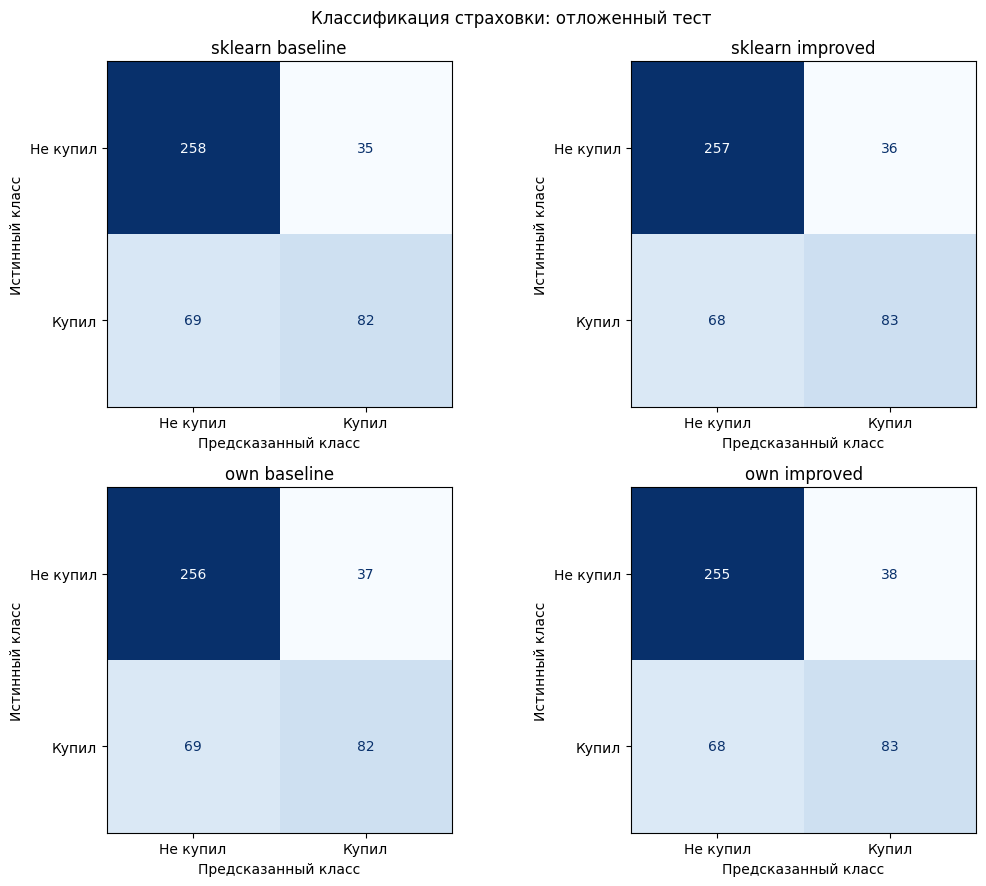

Количество ошибок и правильных ответов:


,model,tn,fp,fn,tp
0,sklearn baseline,258,35,69,82
1,sklearn improved,257,36,68,83
2,own baseline,256,37,69,82
3,own improved,255,38,68,83


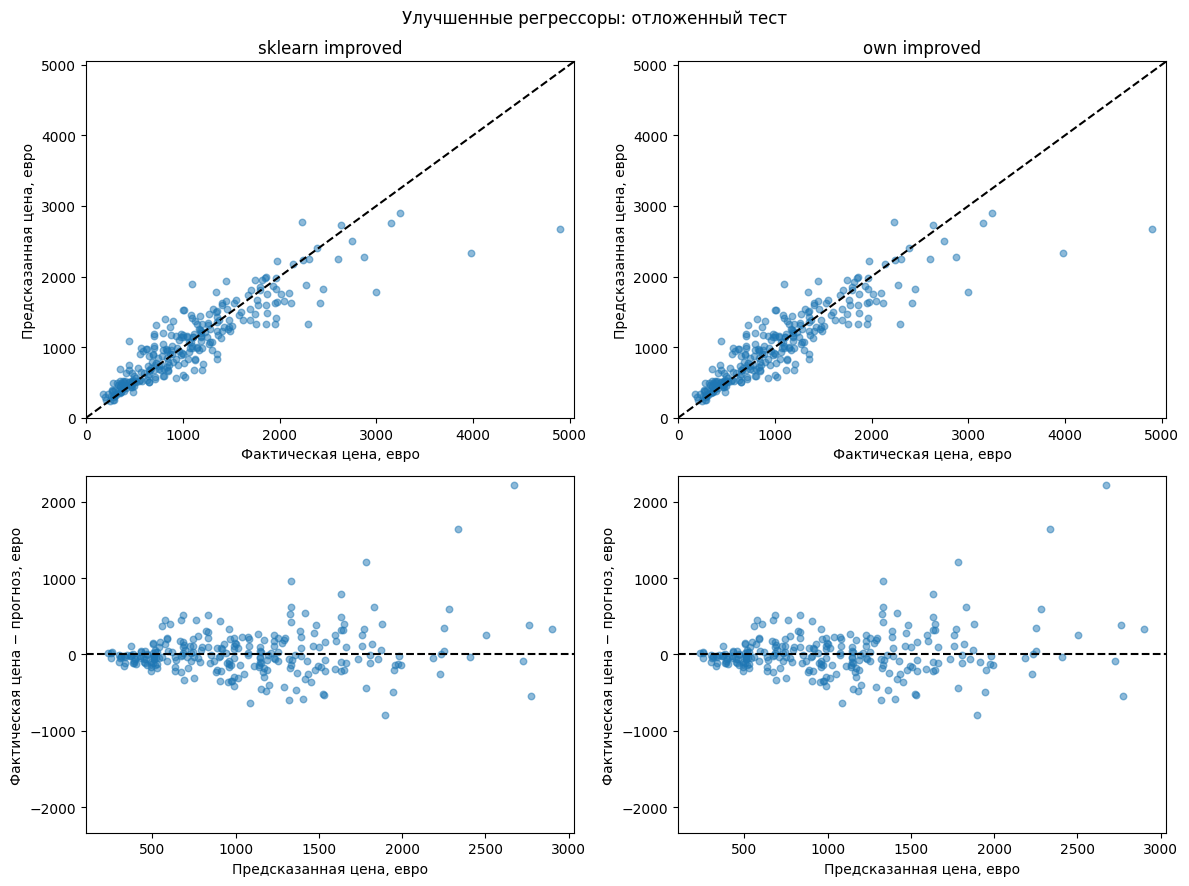

Архив результатов подготовлен: lab1_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
"""Графики и выгрузка результатов ЛР1.

Матрицы ошибок, графики регрессии и архив результатов с настройками.
"""

import importlib.metadata
import zipfile
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

figures_dir = results_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Строим матрицы ошибок всех четырёх классификаторов.
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
confusion_rows = []
for ax, name in zip(axes.flat, final_models_cls):
    predicted = final_predictions_cls[name].to_numpy()
    ConfusionMatrixDisplay.from_predictions(
        y_test_cls, predicted, labels=[0, 1],
        display_labels=["Не купил", "Купил"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")
    tn, fp, fn, tp = confusion_matrix(
        y_test_cls, predicted, labels=[0, 1],
    ).ravel()
    confusion_rows.append({
        "model": name, "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    })

fig.suptitle("Классификация страховки: отложенный тест")
fig.tight_layout()
fig.savefig(figures_dir / "lab1_confusion_matrices.png", dpi=180)
plt.show()

confusion_table = pd.DataFrame(confusion_rows)
confusion_table.to_csv(
    results_dir / "lab1_confusion_counts.csv", index=False,
)
print("Количество ошибок и правильных ответов:")
display(confusion_table)

# Строим прогнозы и остатки двух улучшенных регрессоров.
selected_names = ["sklearn improved", "own improved"]
actual = y_test_reg.to_numpy()
plot_limit = max(
    actual.max(),
    *(final_predictions_reg[name].max() for name in selected_names),
) * 1.03
residual_limit = max(
    np.abs(actual - final_predictions_reg[name].to_numpy()).max()
    for name in selected_names
) * 1.05

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for column, name in enumerate(selected_names):
    predicted = final_predictions_reg[name].to_numpy()
    ax = axes[0, column]
    ax.scatter(actual, predicted, alpha=0.5, s=22)
    ax.plot([0, plot_limit], [0, plot_limit], "--", color="black")
    ax.set_xlim(0, plot_limit)
    ax.set_ylim(0, plot_limit)
    ax.set_title(name)
    ax.set_xlabel("Фактическая цена, евро")
    ax.set_ylabel("Предсказанная цена, евро")

    ax = axes[1, column]
    ax.scatter(predicted, actual - predicted, alpha=0.5, s=22)
    ax.axhline(0, linestyle="--", color="black")
    ax.set_ylim(-residual_limit, residual_limit)
    ax.set_xlabel("Предсказанная цена, евро")
    ax.set_ylabel("Фактическая цена − прогноз, евро")

fig.suptitle("Улучшенные регрессоры: отложенный тест")
fig.tight_layout()
fig.savefig(figures_dir / "lab1_regression_errors.png", dpi=180)
plt.show()

# Сохраняем части CV в координатах строк исходных CSV.
for name, positions, groups, folds in [
    ("travel", train_idx_cls, groups_cls, cv_folds_cls),
    ("laptops", train_idx_reg, groups_reg, cv_folds_reg),
]:
    validation_fold = np.full(len(positions), -1, dtype=int)
    for fold_number, (_, validation_positions) in enumerate(folds):
        assert (validation_fold[validation_positions] == -1).all()
        validation_fold[validation_positions] = fold_number
    assert (validation_fold >= 0).all()
    pd.DataFrame({
        "row_position": positions,
        "group_id": groups[positions],
        "validation_fold": validation_fold,
    }).to_csv(split_dir / f"{name}_cv.csv", index=False)

# Записываем версии библиотек и зафиксированные настройки.
package_names = [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn",
]
package_versions = {
    name: importlib.metadata.version(name) for name in package_names
}
settings = {
    "lab": 1,
    "algorithm": "KNN",
    "python": sys.version.split()[0],
    "random_state": RANDOM_STATE,
    "packages": package_versions,
    "classification": {
        "features": X_train_cls.columns.tolist(),
        "improved_parameters": params_cls,
        "numeric_scaling": False,
        "selection_metric": "macro_f1",
    },
    "regression": {
        "features": X_train_reg.columns.tolist(),
        "improved_parameters": params_reg,
        "numeric_scaling": "StandardScaler",
        "ppi": False,
        "log_target": False,
        "selection_metric": "mae",
    },
    "timing": "One run; fit/predict include preprocessing; proba timed separately",
}
(results_dir / "lab1_settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2), encoding="utf-8",
)

# Упаковываем результаты, рисунки, разбиения и версии зависимостей.
# Архив содержит результаты и разбиения; файл ipynb сохраняется отдельно.
archive_path = Path("/content/lab1_artifacts.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for directory, prefix in [
        (results_dir, Path("results")),
        (split_dir, Path("data/splits")),
    ]:
        for path in sorted(directory.rglob("*")):
            if path.is_file():
                archive.write(path, str(prefix / path.relative_to(directory)))
    archive.writestr(
        "requirements.txt",
        "\n".join(f"{name}=={version}" for name, version in package_versions.items())
        + "\n",
    )

print("Архив результатов подготовлен:", archive_path.name)
files.download(str(archive_path))


### Интерпретация матриц и остатков

Улучшенный библиотечный классификатор выявил 83 из 151 покупателя,
пропустил 68 покупателей и дал 36 ложных положительных прогнозов.
По сравнению с исходным вариантом найден один дополнительный покупатель
ценой одного дополнительного ложного срабатывания. Accuracy сохранилась,
а macro-F1 увеличилась незначительно. Собственный улучшенный классификатор
также выявил 83 покупателя, но дал 38 ложных положительных прогнозов.

На графиках регрессии многие прогнозы расположены вблизи линии y=x,
однако есть крупные ошибки. Например, улучшенная библиотечная модель
оценила ноутбук стоимостью 4899 евро примерно в 2674.17 евро; остаток
составил около 2224.83 евро. Для части дорогих ноутбуков видна недооценка.
Разброс остатков у более высоких прогнозов больше, чем у низких.
Средняя абсолютная ошибка поэтому не означает одинаковой точности
для всех ценовых диапазонов. Графики своей и библиотечной моделей близки.

Этот разбор описывает ошибки зафиксированных моделей. Настройки по
результатам тестовой выборки не подбираются.


## Итоговые выводы

В работе сравнивались четыре варианта KNN для классификации покупки
страховки и четыре варианта для прогноза цены ноутбука.

Масштабирование помогло регрессии, но не улучшило классификацию при
стандартных настройках. После подбора параметров для страховки выбран
KNN без масштабирования: 5 соседей, веса по расстоянию, p=2.
Для ноутбуков выбран StandardScaler, 5 соседей, веса по расстоянию и p=1.
PPI и логарифм цены на CV не уменьшили MAE и в итоговый вариант не вошли.

На тесте macro-F1 библиотечной классификации вырос с 0.7221 до 0.7233.
Прирост небольшой: модель нашла на одного покупателя больше, но добавила
одно ложное срабатывание. MAE регрессии снизилась с 237.22 до 196.26 евро,
то есть примерно на 17.3%.

Собственный улучшенный KNN получил macro-F1 = 0.7191 и MAE = 196.12 евро.
Результаты близки к sklearn. Проверки на небольших искусственных данных
также прошли: отдельно проверены два расстояния, два вида весов,
нулевые расстояния и равные голоса.

Ограничения видны по ошибкам. Классификатор находит около 55% покупателей,
остальных пропускает. В регрессии есть большие ошибки на отдельных дорогих
ноутбуках, поэтому средняя MAE не описывает точность каждого прогноза.

Параметры выбирались на групповой CV внутри train, затем зафиксированные
варианты оценивались на тесте. Время обучения и предсказания измерялось
вместе с предобработкой; результаты времени относятся к одному запуску.
